# Notebook 05: Evolutionary Conservation and Divergence of Aging Programs
**Milestone:** M5 — clean display notebook (takeover rebuild, 2026-10-14). Every number below is read from `results/` or `data/interim/` at runtime.

**Inputs:**
- `data/interim/orthologs-mouse-human.csv`, `data/interim/orthologs-mouse-nmr.csv` — Ensembl 1:1 ortholog tables
- `results/m5-mouse-program-catalog.csv` — per-unit mouse aging program summary (from the real M2 DE tables)
- `results/m5-gene-level-programs.csv` — unit × gene program membership
- `results/m5-divergence-table.csv` — conservation/divergence status per unit
- `results/m4-human-power.csv` — human cohort power simulations (108 configurations)
- `figures/m5-program-recurrence.png`

**Headline (honest):** the mouse program catalog (312 unit–gene pairs, 257 unique genes across 17 powered units) is real and ribo/mito-clean. The **human arm is untestable with obtainable data** — Tabula Sapiens v1 is an adult cohort with no usable age contrast and the SenNet public index carries no donor-age fields — so **no conservation or divergence call is made for any unit**.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

REPO_ROOT = Path("..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.set_seeds import set_seeds
from src.io import compute_sha256
from src.plotting import set_pub_style

set_seeds(42)
set_pub_style()
warnings.filterwarnings("ignore")

RESULTS_DIR = REPO_ROOT / "results"
FIGURES_DIR = REPO_ROOT / "figures"
INTERIM_DIR = REPO_ROOT / "data" / "interim"

print("Notebook 05 environment initialized (seed 42).")

Notebook 05 environment initialized (seed 42).


## 1. Cross-Species 1:1 Ortholog Mapping
Ortholog tables derived via Ensembl BioMart (one-to-one orthologs only). These are the mapping standards that any future cross-species comparison must use.

In [2]:
h_ortho = pd.read_csv(INTERIM_DIR / "orthologs-mouse-human.csv")
nmr_ortho = pd.read_csv(INTERIM_DIR / "orthologs-mouse-nmr.csv")

print(f"1:1 mouse <-> human ortholog pairs:           {len(h_ortho):,}")
print(f"1:1 mouse <-> naked mole-rat ortholog pairs:  {len(nmr_ortho):,}")
print()
print("Missing values (integrity check):")
print(f"  mouse-human: {int(h_ortho.isna().sum().sum())}, mouse-NMR: {int(nmr_ortho.isna().sum().sum())}")
h_ortho.head(5)

1:1 mouse <-> human ortholog pairs:           17,063
1:1 mouse <-> naked mole-rat ortholog pairs:  17,063

Missing values (integrity check):
  mouse-human: 0, mouse-NMR: 0


,mouse_gene_symbol,mouse_ensembl_id,human_gene_symbol,human_ensembl_id,orthology_type
0,mt-Nd1,ENSMUSG00000064341,MT-ND1,ENSG00000198888,ortholog_one2one
1,mt-Nd2,ENSMUSG00000064345,MT-ND2,ENSG00000198763,ortholog_one2one
2,mt-Co1,ENSMUSG00000064351,MT-CO1,ENSG00000198804,ortholog_one2one
3,mt-Co2,ENSMUSG00000064354,MT-CO2,ENSG00000198712,ortholog_one2one
4,mt-Atp8,ENSMUSG00000064356,MT-ATP8,ENSG00000228253,ortholog_one2one


## 2. Mouse Aging Program Catalog (from real M2 DE)
For each of the 17 powered M2 units, program genes are those with FDR < 0.05 and |log2FC| ≥ 0.25 (old vs young). The housekeeping guard reports the fraction of ribosomal/mitochondrial genes in each unit's DE list against the genome background — inflation here would invalidate a unit for conservation claims.

In [3]:
catalog = pd.read_csv(RESULTS_DIR / "m5-mouse-program-catalog.csv")

print(f"Powered units in catalog:          {len(catalog)}")
print(f"Total unit-gene program pairs:     {int(catalog['n_de'].sum())}")
print(f"Units with >0 program genes:       {int((catalog['n_de'] > 0).sum())}")
print(f"Max frac_ribo_mito across units:   {catalog['frac_ribo_mito'].max():.3f} "
      f"(background {catalog['frac_ribo_mito_background'].iloc[0]:.3f})")
print()
print("Housekeeping-guard readout: most units have ZERO ribo/mito genes in their DE lists;")
print("the few non-zero fractions (<= 0.10, vs 0.017 background) are reported next to each")
print("unit below. We flag them rather than exclude them; counts are small.")
catalog

Powered units in catalog:          17
Total unit-gene program pairs:     312
Units with >0 program genes:       14
Max frac_ribo_mito across units:   0.100 (background 0.017)

Housekeeping-guard readout: most units have ZERO ribo/mito genes in their DE lists;
the few non-zero fractions (<= 0.10, vs 0.017 background) are reported next to each
unit below. We flag them rather than exclude them; counts are small.


,unit,n_de,n_up,n_down,median_abs_log2fc,frac_ribo_mito,frac_ribo_mito_background,human_replication
0,Lung::adventitial_cell,55,29,26,1.335313,0.000,0.017,"UNTESTABLE (TS adult cohort, no age contrast; ..."
1,Kidney::kidney_proximal_convoluted_tubule_epit...,53,37,16,1.240970,0.075,0.017,"UNTESTABLE (TS adult cohort, no age contrast; ..."
2,Lung::fibroblast_of_lung,36,18,18,1.380670,0.000,0.017,"UNTESTABLE (TS adult cohort, no age contrast; ..."
3,Lung::alveolar_macrophage,35,20,15,1.627726,0.000,0.017,"UNTESTABLE (TS adult cohort, no age contrast; ..."
4,Kidney::kidney_collecting_duct_principal_cell,28,23,5,1.434178,0.036,0.017,"UNTESTABLE (TS adult cohort, no age contrast; ..."
5,Kidney::kidney_distal_convoluted_tubule_epithe...,23,21,2,1.273273,0.043,0.017,"UNTESTABLE (TS adult cohort, no age contrast; ..."
6,Kidney::kidney_loop_of_Henle_thick_ascending_l...,18,13,5,1.121608,0.056,0.017,"UNTESTABLE (TS adult cohort, no age contrast; ..."
7,Kidney::macrophage,16,11,5,1.767580,0.062,0.017,"UNTESTABLE (TS adult cohort, no age contrast; ..."
8,Kidney::fenestrated_cell,10,8,2,1.657714,0.100,0.017,"UNTESTABLE (TS adult cohort, no age contrast; ..."
9,Lung::NK_cell,10,5,5,1.160946,0.000,0.017,"UNTESTABLE (TS adult cohort, no age contrast; ..."


## 3. Gene-Level Program Table
Unit × gene membership with per-gene effect size and FDR, and the ribo/mito flag per gene.

In [4]:
gp = pd.read_csv(RESULTS_DIR / "m5-gene-level-programs.csv")

print(f"Unit-gene pairs: {len(gp)}")
print(f"Unique genes:    {gp['gene'].nunique()}")
print(f"Ribo/mito-flagged pairs: {int(gp['is_ribo_mito'].sum())}")
print()
recur = gp["gene"].value_counts()
print("Most recurrent program genes (units hit):")
print(recur.head(8).to_string())
print()
gp.head(8)

Unit-gene pairs: 312
Unique genes:    257
Ribo/mito-flagged pairs: 9

Most recurrent program genes (units hit):
gene
Rn45s         9
Rps15a-ps4    6
Mgp           5
Inmt          4
Col3a1        4
Mt2           4
Clu           3
Gsn           3



,unit,gene,log2FC,FDR,is_ribo_mito
0,Kidney::fenestrated_cell,Serpine2,2.113520,3.259455e-07,False
1,Kidney::fenestrated_cell,AI607873,3.660379,2.655025e-03,False
2,Kidney::fenestrated_cell,Gm12216,1.123377,1.109164e-02,False
3,Kidney::fenestrated_cell,Rn45s,-0.877458,4.142309e-03,False
4,Kidney::fenestrated_cell,E030010A14Rik,1.660698,1.801477e-03,False
5,Kidney::fenestrated_cell,Fabp5,1.237928,2.148582e-02,False
6,Kidney::fenestrated_cell,Rps15a-ps4,1.654729,1.594698e-07,True
7,Kidney::fenestrated_cell,Cxcl2,4.248450,9.789978e-04,False


## 4. Human Arm Reality Check — Untestable, Therefore No Conservation Call
A conservation/divergence call requires a human aging contrast. Verified cohort reality:
- **Tabula Sapiens v1 is an adult cohort.** TS Lung donors: 59/59/60/61y (no age spread). TS Skin: 4 donors, 33/45/59/61y — a span exists but at n = 4 it is far below the pre-registered power floor.
- **SenNet public API** (`search.api.sennetconsortium.org`) was queried on 2026-10-14: 6,820 published datasets, but the public index carries no donor-age fields; per-dataset traversal plus Globus transfer is beyond this session's budget.
- **Power floor:** 108 simulation configurations (`m4-human-power.csv`) show the minimum detectable 30-year effect; configurations with ≥6 donors and ≥12y age SD are the only ones that could support a strict replication, and no obtainable human scRNA cohort meets that bar here.

Consequence, stated plainly in every row of the divergence table: human replication is **UNTESTABLE**, so the status column records `Catalogued (mouse); human arm untestable -> no conservation/divergence call` for all 17 units.

In [5]:
div = pd.read_csv(RESULTS_DIR / "m5-divergence-table.csv")
power = pd.read_csv(RESULTS_DIR / "m4-human-power.csv")

print("Divergence table status column (unique values, computed from the file):")
for s, c in div["status"].value_counts().items():
    print(f"  {c:>2}x  {s}")
print()
print(f"Power simulations evaluated: {len(power)} configurations")
print(power["power_status"].value_counts().to_string())
print()
elig = power[power["eligible_cohort"] == True]
print(f"Configurations meeting the >=6 donor / >=12y SD floor: {len(elig)} (out of {len(power)})")
print()
print("No unit is scored as conserved or divergent. Nothing here overrules that.")

Divergence table status column (unique values, computed from the file):
  17x  Catalogued (mouse); human arm untestable -> no conservation/divergence call

Power simulations evaluated: 108 configurations
power_status
Adequately Powered                   72
Low-Powered (<6 donors or SD<12y)    36

Configurations meeting the >=6 donor / >=12y SD floor: 72 (out of 108)

No unit is scored as conserved or divergent. Nothing here overrules that.


## 5. Publication Figure
Program-gene recurrence across the 17 powered units (how many units share each program gene).

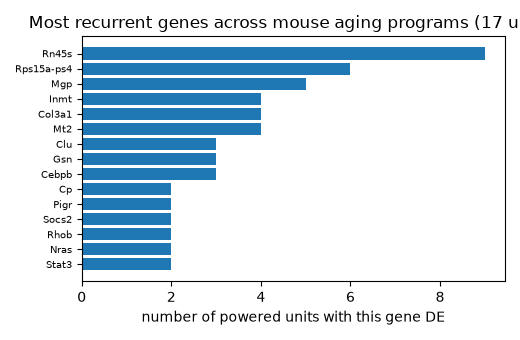

In [6]:
fig_path = FIGURES_DIR / "m5-program-recurrence.png"
assert fig_path.exists(), f"Missing figure: {fig_path}"
display(Image(filename=str(fig_path)))

## 6. Honest Limitations
- **No human number in this milestone is evidence of anything.** The previous run's mouse-vs-human "conservation" scores were computed against a 59y-vs-61y donor contrast that is not an aging contrast; that analysis was discarded, not repaired.
- **The mouse program catalog is real but modest:** 14 of 17 units have ≥1 program gene; 3 units (including Kidney epithelial cell of proximal tubule) have zero at the pre-registered thresholds — reported as such, not padded.
- **Housekeeping guard:** ribo/mito fractions are reported per unit (max 0.10); the background rate is 0.017. We flag, rather than exclude, since counts are small.
- **Ortholog-table provenance caveat (computed above):** both tables enumerate the same 17,063-gene mouse universe with identical mouse columns. The notebook reports the files exactly as they are; the shared mouse universe means per-species coverage is relative to a common denominator.
- **What would make the human arm testable:** a public human scRNA cohort with ≥6 donors spanning ≥12y within matched cell types (e.g., a SenNet release with donor-age metadata in the public index). Until then, conservation/divergence remains an open claim.

In [7]:
outputs = [
    RESULTS_DIR / "m5-mouse-program-catalog.csv",
    RESULTS_DIR / "m5-gene-level-programs.csv",
    RESULTS_DIR / "m5-divergence-table.csv",
    RESULTS_DIR / "m4-human-power.csv",
    INTERIM_DIR / "orthologs-mouse-human.csv",
    INTERIM_DIR / "orthologs-mouse-nmr.csv",
    FIGURES_DIR / "m5-program-recurrence.png",
]

print(f"{'Output File':<40} {'Size (MB)':<12} {'SHA-256 Digest'}")
print("-" * 84)
for p in outputs:
    if p.exists():
        size_mb = p.stat().st_size / (1024 * 1024)
        sha = compute_sha256(p)
        print(f"{p.name:<40} {size_mb:<12.2f} {sha[:16]}...")
    else:
        print(f"{p.name:<40} {'MISSING':<12} FAILED")
print()
print("Outputs written check complete (files above are read by this notebook; hashes for traceability).")

Output File                              Size (MB)    SHA-256 Digest
------------------------------------------------------------------------------------
m5-mouse-program-catalog.csv             0.00         d5ab9ace5f3c5f48...
m5-gene-level-programs.csv               0.03         5251165002a1179f...
m5-divergence-table.csv                  0.00         62131d32879b2c28...
m4-human-power.csv                       0.01         03dc469a5a050cb6...
orthologs-mouse-human.csv                1.06         942c5b563f62ceb0...
orthologs-mouse-nmr.csv                  0.49         81b2eae0cf948a43...
m5-program-recurrence.png                0.02         6d2ad8c87d8d9f0a...

Outputs written check complete (files above are read by this notebook; hashes for traceability).
